# CPGs on the gecko

Which of ARIEL's seven CPGs makes the prebuilt gecko walk furthest? Every CPG
gets the same body, world, time and search budget:

* Body: `gecko()`, 8 hinge joints, one oscillator per joint, all oscillators
  coupled to each other.
* World: `SimpleFlatWorld`, 10 s of simulated time per trial.
* Control: `Controller` calls the CPG every 4 physics steps (15 ms at the
  3.75 ms timestep) with the simulation time; the CPG integrates over that
  time.
* Score: the distance in the floor plane between the core's start and end
  positions, in metres.
* Search: CMA-ES from nevergrad over the CPG's parameters, each scaled to the
  range the CPG samples its initial values from. 150 trials per run, three
  runs (seeds 0, 1, 2) per CPG.

Three CPGs also get sensory feedback before each call:

* `AdaptiveHopfCPG`: the measured joint angle minus the commanded one, so its
  frequencies can drift towards what the body actually does.
* `TegotaeCPG` and `LearnableTegotaeCPG`: the load on each joint's limb, the
  vertical force of the floor on every body that joint moves, in newtons. The
  next section measures them on the resting gecko and checks that the floor
  carries its whole weight. For `LearnableTegotaeCPG` the search also tunes
  the 51 weights of its three networks, as the paper does with PGPE.

The notebook is marked slow (about 22 minutes); `tools/run_notebooks.py`
runs it only with `--slow` or when named.

In [1]:
# Standard library
import time

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel.body_phenotypes.robogen_lite.prebuilt_robots.gecko import gecko
from ariel.simulation import (
    AdaptiveHopfCPG,
    Controller,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SimpleFlatWorld,
    SwingStanceCPG,
    TegotaeCPG,
    Tracker,
    create_fully_connected_adjacency,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 72
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
SECONDS = 10.0
STEPS_PER_CONTROL = 4
BUDGET = 150
SEEDS = [0, 1, 2]

## The trial

One world is compiled once and reset before every trial.

In [2]:
world = SimpleFlatWorld()
world.spawn(gecko().spec, position=(0, 0, 0.1))
model = world.compile()
data = mujoco.MjData(model)
core = next(
    i for i in range(model.nbody) if model.body(i).name.endswith("core")
)
# qpos address of the joint each actuator drives
joint_qpos = model.jnt_qposadr[model.actuator_trnid[:, 0]]
adjacency = create_fully_connected_adjacency(model.nu)

# limb[a, b] is 1 when actuator a's joint moves body b
robot = model.body_rootid == model.body_rootid[core]
joint_body = model.jnt_bodyid[model.actuator_trnid[:, 0]]
limb = np.zeros((model.nu, model.nbody))
for body in range(model.nbody):
    ancestor = body
    while ancestor != 0:
        limb[joint_body == ancestor, body] = 1.0
        ancestor = model.body_parentid[ancestor]
contact_force = np.zeros(6)


def floor_forces(d):
    """Return the vertical floor force on each body of the robot.

    Returns
    -------
    np.ndarray
        One force per body, in newtons.
    """
    per_body = np.zeros(model.nbody)
    for index in range(d.ncon):
        contact = d.contact[index]
        first = model.geom_bodyid[contact.geom1]
        second = model.geom_bodyid[contact.geom2]
        if robot[first] == robot[second]:
            continue  # the robot touching itself, or two pieces of the world
        mujoco.mj_contactForce(model, d, index, contact_force)
        on = first if robot[first] else second
        per_body[on] += contact_force[0] * abs(contact.frame[2])
    return per_body


def limb_loads(d):
    """Sum the vertical floor force on the bodies each joint moves.

    Returns
    -------
    np.ndarray
        One load per actuator, in newtons.
    """
    return limb @ floor_forces(d)


SETTLE = 2.0  # seconds for the gecko to come to rest, joints at 0
mujoco.mj_resetData(model, data)
while data.time < SETTLE:
    mujoco.mj_step(model, data)
weight = model.body_mass[robot].sum() * -model.opt.gravity[2]
on_floor = floor_forces(data).sum()
resting_loads = limb_loads(data)
console.print(
    f"weight {weight:.2f} N, floor force {on_floor:.2f} N, limb loads"
    f" {np.round(resting_loads, 2)} N"
)

console.print(
    f"{model.nu} actuators, timestep {model.opt.timestep * 1000:.1f} ms"
)


def trial(cpg):
    """Run one 10 s trial.

    Returns
    -------
    float
        The distance the core travelled in the floor plane, in metres.
    """
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    start = data.xpos[core, :2].copy()

    def callback(_model, d, *_args, **_kwargs):
        if isinstance(cpg, AdaptiveHopfCPG):
            cpg.set_input(d.qpos[joint_qpos] - d.ctrl)
        return cpg.forward(d.time).numpy()

    controller = Controller(
        controller_callback_function=callback,
        time_steps_per_ctrl_step=STEPS_PER_CONTROL,
        time_steps_per_save=10**9,
        tracker=Tracker(mujoco.mjtObj.mjOBJ_BODY, "core", ["xpos"]),
    )
    controller.tracker.setup(world.spec, data)
    mujoco.set_mjcb_control(controller.set_control)
    try:
        while data.time < SECONDS:
            mujoco.mj_step(model, data)
            # Read the loads after the step: inside the control callback the
            # contacts are new but the contact forces are still the last
            # step's, so mj_contactForce would read stale values there.
            if isinstance(cpg, TegotaeCPG):  # LearnableTegotaeCPG too
                cpg.set_input(limb_loads(data))
    finally:
        mujoco.set_mjcb_control(None)
    return float(np.linalg.norm(data.xpos[core, :2] - start))

weight 24.82 N, floor force 24.82 N, limb loads [8.48 8.48 0.98 0.98 0.98 0.98 4.24 4.24] N

8 actuators, timestep 3.8 ms

## The search

CMA-ES works in the unit cube; each point is scaled to the CPG's own
parameter bounds (for example `w` from 0 to 4 pi rad/s, amplitudes from 0 to
pi/2 rad) before it is set. Each search starts from the parameters the CPG
drew at random with that seed, not from the middle of the cube: the middle of
the Tegotae amplitude range (-pi/2 to pi/2) is a gecko that does not move.

In [3]:
def optimise(cpg_class, seed):
    """Search one CPG's parameters with CMA-ES.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        The score of every trial in order, and the best parameters.
    """
    cpg = cpg_class(adjacency, seed=seed)
    lower, upper = (b.numpy() for b in cpg.parameter_bounds())
    parametrization = ng.p.Array(
        shape=(cpg.num_of_parameters,), lower=0, upper=1
    )
    # start from the CPG's own seeded random parameters
    parametrization.value = (cpg.get_flat_params().numpy() - lower) / (
        upper - lower
    )
    parametrization.random_state = np.random.RandomState(seed)
    optimizer = ng.optimizers.CMA(
        parametrization=parametrization, budget=BUDGET
    )
    scores = []
    best, best_params = -1.0, None
    for _ in range(BUDGET):
        candidate = optimizer.ask()
        params = lower + candidate.value * (upper - lower)
        cpg.set_flat_params(params.astype(np.float32))
        score = trial(cpg)
        optimizer.tell(candidate, -score)
        scores.append(score)
        if score > best:
            best, best_params = score, params
    return np.array(scores), best_params


results = {}
seconds_per_trial = {}
for cpg_class in MODELS:
    started = time.perf_counter()
    runs = [optimise(cpg_class, seed) for seed in SEEDS]
    elapsed = time.perf_counter() - started
    seconds_per_trial[cpg_class.__name__] = elapsed / (BUDGET * len(SEEDS))
    results[cpg_class.__name__] = runs
    best = [scores.max() for scores, _ in runs]
    console.print(
        f"{cpg_class.__name__:16s} best per seed {np.round(best, 3)} m"
        f"  ({elapsed:.0f} s)"
    )

HopfCPG          best per seed [0.21  0.182 0.171] m  (119 s)

AdaptiveHopfCPG  best per seed [0.183 0.186 0.149] m  (146 s)

PhaseCPG         best per seed [0.233 0.226 0.167] m  (117 s)

SwingStanceCPG   best per seed [0.224 0.138 0.173] m  (131 s)

NaCPG            best per seed [0.155 0.227 0.275] m  (154 s)

TegotaeCPG       best per seed [0.068 0.046 0.153] m  (172 s)

LearnableTegotaeCPG best per seed [0.097 0.078 0.187] m  (225 s)

## Results

Best distance found so far against the number of trials, median of the three
seeds, with the range between the worst and the best seed shaded.

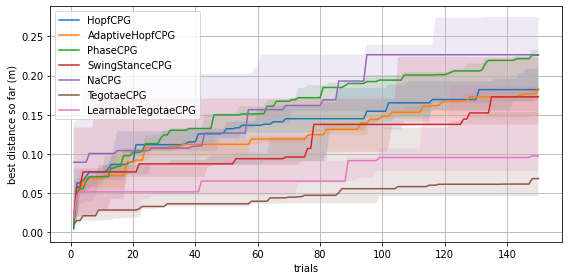

CPG              params median best  worst   best s/trial

HopfCPG              32       0.182  0.171  0.210    0.26

AdaptiveHopfCPG      32       0.183  0.149  0.186    0.33

PhaseCPG             32       0.226  0.167  0.233    0.26

SwingStanceCPG       40       0.173  0.138  0.224    0.29

NaCPG                40       0.227  0.155  0.275    0.34

TegotaeCPG           40       0.068  0.046  0.153    0.38

LearnableTegotaeCPG     83       0.097  0.078  0.187    0.50

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, runs in results.items():
    curves = np.array([np.maximum.accumulate(scores) for scores, _ in runs])
    trials = np.arange(1, BUDGET + 1)
    ax.plot(trials, np.median(curves, axis=0), label=name)
    ax.fill_between(trials, curves.min(axis=0), curves.max(axis=0), alpha=0.15)
ax.set_xlabel("trials")
ax.set_ylabel("best distance so far (m)")
ax.legend()
ax.grid(visible=True)
fig.tight_layout()
plt.show()

console.print(
    f"{'CPG':16s} {'params':>6s} {'median best':>11s} {'worst':>6s}"
    f" {'best':>6s} {'s/trial':>7s}"
)
table = {}
for name, runs in results.items():
    best = np.array([scores.max() for scores, _ in runs])
    table[name] = best
    n_params = len(runs[0][1])
    console.print(
        f"{name:16s} {n_params:6d} {np.median(best):11.3f} {best.min():6.3f}"
        f" {best.max():6.3f} {seconds_per_trial[name]:7.2f}"
    )

## The best gait of each CPG

The joint angles of each CPG's best parameters over the first 3 s, replayed
in the same world.

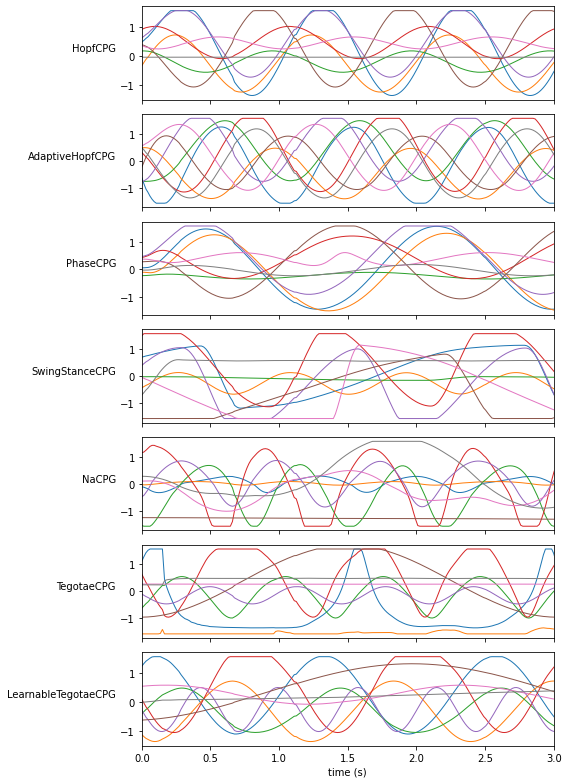

In [5]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(8, 11), sharex=True)
replayed = {}
for ax, cpg_class in zip(axes, MODELS, strict=True):
    runs = results[cpg_class.__name__]
    scores, params = max(runs, key=lambda run: run[0].max())
    cpg = cpg_class(adjacency, angle_tracking=True)
    cpg.set_flat_params(params.astype(np.float32))
    replayed[cpg_class.__name__] = (trial(cpg), scores.max())
    history = np.array(cpg.angle_history)
    times = np.arange(len(history)) * STEPS_PER_CONTROL * model.opt.timestep
    ax.plot(times, history, linewidth=1)
    ax.set_xlim(0, 3)
    ax.set_ylabel(cpg_class.__name__, rotation=0, ha="right")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

## Checks

Every CPG must move the gecko, and replaying the best parameters must give
the same distance (the trial is deterministic).

In [6]:
WALKS = 0.1  # metres in 10 s
WEIGHT_TOLERANCE = 0.02  # share of the weight
assert abs(on_floor - weight) < WEIGHT_TOLERANCE * weight
SAME = 1e-6  # metres
for name, best in table.items():
    assert np.isfinite(best).all(), name
    assert best.max() > WALKS, name
for name, (again, found) in replayed.items():
    assert abs(again - found) < SAME, name